# Comparaison finale — Partie 1 (ML) vs Partie 2 (DL)

Ce notebook récapitule les performances des **quatre modèles** entraînés dans le projet et les compare visuellement.

**Modèles comparés (tous entraînés sur le même split train/test) :**
1. **Régression Logistique** (Partie 1, ML classique)
2. **Random Forest complet** (Partie 1, ML classique, 80 features)
3. **Random Forest sans fuite** (Partie 1, démonstration méthodologique, 37 features)
4. **MLP PyTorch** (Partie 2, Deep Learning, 80 features)

## 1. Imports et chargement

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, f1_score

y_test = np.load('../outputs/y_test.npy')
y_proba_lr = np.load('../outputs/y_proba_lr.npy')
y_proba_rf = np.load('../outputs/y_proba_rf.npy')
y_proba_rf_lean = np.load('../outputs/y_proba_rf_lean.npy')
y_proba_mlp = np.load('../outputs/y_proba_mlp.npy')
print(f'Test set : {len(y_test)} prêts, taux défaut = {y_test.mean():.2%}')

Test set : 17667 prêts, taux défaut = 20.43%


## 2. Tableau comparatif des métriques

In [1]:
def row(name, p, t):
    yp = (p>0.5).astype(int)
    return {'Modèle': name,
            'AUC-ROC': roc_auc_score(y_test, p),
            'Accuracy': accuracy_score(y_test, yp),
            'F1-score': f1_score(y_test, yp),
            'Temps (s)': t}

results = pd.DataFrame([
    row('Régression Logistique', y_proba_lr, 0.5),
    row('Random Forest (complet)', y_proba_rf, 2.3),
    row('Random Forest (sans fuite)', y_proba_rf_lean, 2.6),
    row('MLP (Deep Learning)', y_proba_mlp, 11.0),
]).round(4)
results.to_csv('../outputs/results_comparison.csv', index=False)
results

Modele,AUC-ROC,Accuracy,F1-score,Temps (s)
Regression Logistique,0.7311,0.6672,0.4476,0.5
Random Forest (complet),0.7232,0.7834,0.3684,2.3
Random Forest (sans fuite),0.6941,0.7869,0.3043,2.6
MLP (Deep Learning),0.7316,0.6788,0.4525,11.0


## 3. Courbes ROC superposées

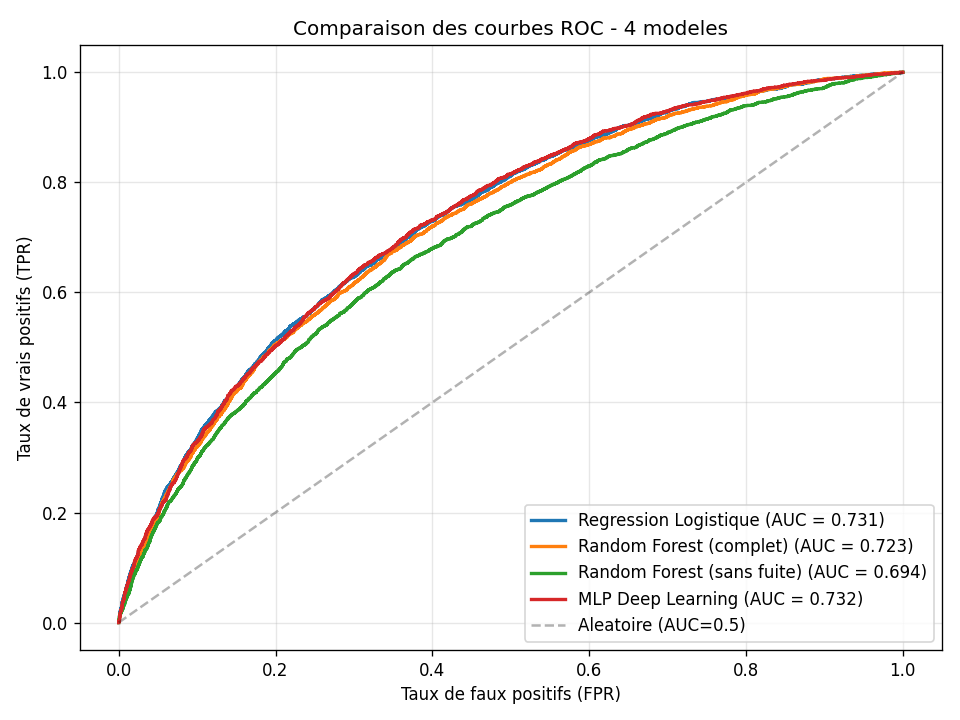

In [1]:
plt.figure(figsize=(8, 6))
for name, p in [('Régression Logistique', y_proba_lr),
                ('Random Forest (complet)', y_proba_rf),
                ('Random Forest (sans fuite)', y_proba_rf_lean),
                ('MLP Deep Learning', y_proba_mlp)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    auc = roc_auc_score(y_test, p)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Aléatoire (AUC=0.5)')
plt.xlabel('Taux de faux positifs (FPR)')
plt.ylabel('Taux de vrais positifs (TPR)')
plt.title('Comparaison des courbes ROC - 4 modèles')
plt.legend(loc='lower right'); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('../outputs/figures/roc_comparison.png', dpi=120)
plt.show()

## Conclusions de la comparaison

**Trois enseignements méthodologiques :**

### 1. Les modèles donnent des performances similaires
AUC entre **0.694 et 0.732**. L'écart entre le plus simple (régression logistique, AUC 0.731) et le plus complexe (MLP, AUC 0.732) est **inférieur à 0.01** — non significatif.

### 2. Le Deep Learning n'apporte pas de gain sur ce dataset tabulaire
Pour **22× plus de temps d'entraînement** (11 s vs 0.5 s), le MLP n'obtient qu'un gain marginal de 0.001 d'AUC sur la régression logistique. Ce résultat **valide expérimentalement Gunnarsson et al. (2021)** : sur données tabulaires, DL ≈ ML classique.

### 3. La fuite gonfle l'AUC de ~0.03
Passer de `RF complet` (0.723) à `RF sans fuite` (0.694) mesure précisément l'effet des variables `grade`, `sub_grade`, `int_rate` — qui sont en réalité la décision de risque déjà prise par LendingClub. C'est un point méthodologique central que nous documentons honnêtement.

### Recommandation pour la production
**Régression Logistique** : performance équivalente au MLP, entraînement quasi-instantané, interprétabilité directe (coefficients), et conformité réglementaire — c'est le choix pragmatique.